# A 12-unit Hopfield example: recall and its limits

**One executable model of associative memory.** Companion to the paper's Hopfield example.

Reproduce the paper's **one pattern, 12 units, three corrupted bits and two ordered sweeps**.
Inspect each update and its energy change, then demonstrate the inverse pattern's equal-energy stability.
This differs from the 32-unit, two-pattern exercise in [notebook 05](05_multistable_dynamics.ipynb).

The shared implementation [paper_examples.py](../src/brainsmodels/paper_examples.py) is used by
both the [figure builder](../src/brainsmodels/clinical_examples.py) and the
[appendix calculation](../src/brainsmodels/clinical_appendix.py). Run all cells in order with
the project's Python kernel. Outputs go to ignored `.build/paper-examples/12_hopfield_12_units/`.


In [1]:
from pathlib import Path
import json
import sys

import numpy as np
import matplotlib.pyplot as plt

# Run from the repository root or code/notebooks in a complete checkout.
here = Path.cwd().resolve()
ROOT = next((p for p in [here, *here.parents]
             if (p / "pyproject.toml").is_file() and (p / "code/src").is_dir()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook inside the brains-to-models checkout.")
sys.path.insert(0, str(ROOT / "code/src"))
from brainsmodels.paper_examples import hopfield_12, hopfield_energy

get_ipython().run_line_magic("matplotlib", "inline")
plt.rcParams.update({"figure.dpi": 115, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
OUTPUT = ROOT / ".build/paper-examples/12_hopfield_12_units"

OUTPUT.mkdir(parents=True, exist_ok=True)

def show_figure(fig, name):
    fig.savefig(OUTPUT / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)


## 1. Specify the pattern and update rule

Store the bipolar pattern
$\xi=(1,1,-1,-1,1,-1,1,-1,-1,1,1,-1)$ using
$W_{ij}=\xi_i\xi_j/12$ for $i\ne j$ and $W_{ii}=0$.
Start from $\xi$ with units **1, 4 and 8** flipped (Python indices `0, 3, 7`).

Update one unit at a time, in order 1 through 12, twice. Its local field is $h_i=\sum_jW_{ij}s_j$.
Set $s_i'=+1$ if $h_i>0$, $-1$ if $h_i<0$, and retain $s_i$ on a zero field.
Later units see earlier updates in the same sweep: this is **asynchronous** updating.
Record the initial state plus 24 updates, giving 25 states.


In [2]:
recall = hopfield_12()
xi, W = recall.pattern, recall.weights
np.testing.assert_array_equal(xi, [1, 1, -1, -1, 1, -1, 1, -1, -1, 1, 1, -1])
assert W.shape == (12, 12) and recall.states.shape == (25, 12)
np.testing.assert_array_equal(W, W.T)
np.testing.assert_array_equal(np.diag(W), np.zeros(12))
assert (np.flatnonzero(recall.states[0] != xi) + 1).tolist() == [1, 4, 8]
np.testing.assert_array_equal(recall.states[-1], xi)
print("Stored:   ", xi.astype(int))
print("Noisy cue:", recall.states[0].astype(int))
print("Retrieved:", recall.states[-1].astype(int))
print("Initial/final energy:", recall.energies[0], recall.energies[-1])

figure_values = json.loads((ROOT / "paper/figures/computed_values.json").read_text())
appendix = json.loads((ROOT / "paper/figures/appendix_values.json").read_text())
for reference in (figure_values, appendix):
    np.testing.assert_allclose(recall.energies, reference["hopfield_energy"], rtol=0, atol=1e-14)
np.testing.assert_allclose(recall.energies[[0, -1]], [-1, -5.5], rtol=0, atol=1e-14)
assert figure_values["hopfield_retrieves_pattern"]


Stored:    [ 1  1 -1 -1  1 -1  1 -1 -1  1  1 -1]
Noisy cue: [-1  1 -1  1  1 -1  1  1 -1  1  1 -1]
Retrieved: [ 1  1 -1 -1  1 -1  1 -1 -1  1  1 -1]
Initial/final energy: -1.0 -5.5


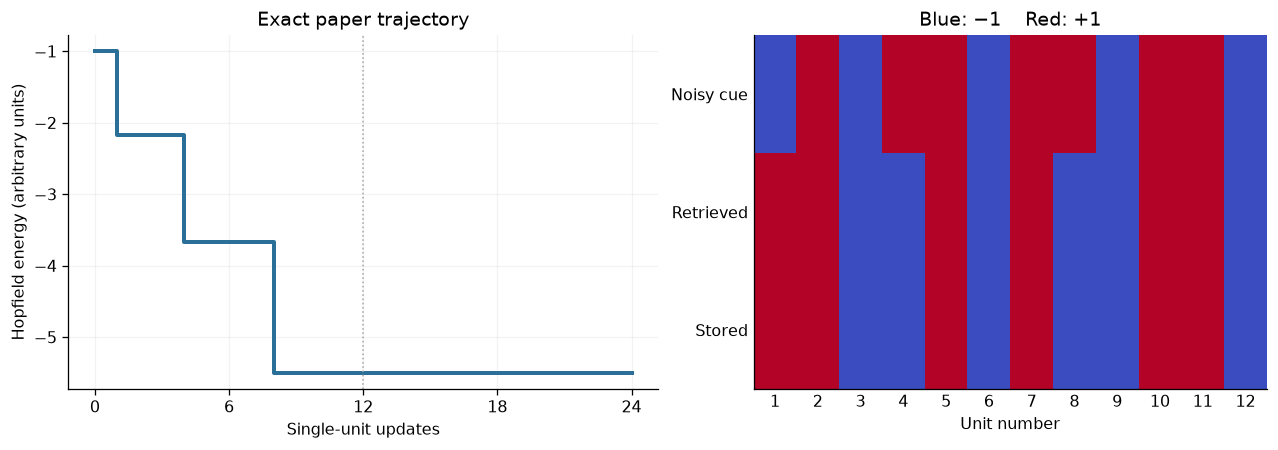

In [3]:
fig, (ax, bx) = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained",
                            gridspec_kw={"width_ratios": [1.15, 1]})
ax.step(np.arange(25), recall.energies, where="post", color="#2a6f97", lw=2.5)
ax.set(xlabel="Single-unit updates", ylabel="Hopfield energy (arbitrary units)",
       title="Exact paper trajectory", xticks=[0, 6, 12, 18, 24])
ax.axvline(12, color="#aaaaaa", ls=":", lw=1)
ax.grid(alpha=.15)
bx.imshow(np.stack([recall.states[0], recall.states[-1], xi]), cmap="coolwarm", vmin=-1, vmax=1,
          aspect="auto", interpolation="nearest")
bx.set(yticks=[0, 1, 2], yticklabels=["Noisy cue", "Retrieved", "Stored"], xlabel="Unit number",
       xticks=range(12), xticklabels=range(1, 13), title="Blue: −1    Red: +1")
bx.tick_params(length=0)
show_figure(fig, "exact_paper_recall")


**Result.** The three wrong bits are repaired and energy falls from $-1$ to $-5.5$.
Flat parts of the curve are updates that leave a bit unchanged; the requested two sweeps include
updates after recall has already reached a fixed point.

## 2. Check the energy argument for every recorded update

For symmetric $W$ with zero diagonal,

$$E(s)=-\tfrac12 s^TWs,\qquad E(s')-E(s)=-(s_i'-s_i)h_i\le0.$$

Only unit $i$ may change at a step. Choosing its sign to agree with the local field gives the
inequality. This is a mathematical Lyapunov function in arbitrary units, not a measurement of brain
metabolism. For this **single-pattern** weight matrix, an independent expression is
$E(s)=-[(\xi^Ts)^2-12]/24$ for bipolar states.


In [4]:
overlap_sum = recall.states @ xi
independent_energy = -(overlap_sum**2 - 12) / 24
np.testing.assert_allclose(recall.energies, independent_energy, rtol=0, atol=1e-14)
assert np.all(np.diff(recall.energies) <= 1e-12)

print("Step  Unit  Before→after   Local field    ΔE")
for step, (unit, field) in enumerate(zip(recall.units, recall.fields)):
    before, after = recall.states[step:step+2]
    delta = recall.energies[step+1] - recall.energies[step]
    assert np.count_nonzero(before != after) <= 1
    assert np.isclose(delta, -(after[unit] - before[unit]) * field, atol=1e-14)
    print(f"{step+1:>4}  {unit+1:>4}     {int(before[unit]):+d} → {int(after[unit]):+d}"
          f"       {field: .4f}     {delta: .4f}")


Step  Unit  Before→after   Local field    ΔE
   1     1     -1 → +1        0.5833     -1.1667
   2     2     +1 → +1        0.5833      0.0000
   3     3     -1 → -1       -0.5833      0.0000
   4     4     +1 → -1       -0.7500     -1.5000
   5     5     +1 → +1        0.7500      0.0000
   6     6     -1 → -1       -0.7500      0.0000
   7     7     +1 → +1        0.7500      0.0000
   8     8     +1 → -1       -0.9167     -1.8333
   9     9     -1 → -1       -0.9167      0.0000
  10    10     +1 → +1        0.9167      0.0000
  11    11     +1 → +1        0.9167      0.0000
  12    12     -1 → -1       -0.9167      0.0000
  13     1     +1 → +1        0.9167      0.0000
  14     2     +1 → +1        0.9167      0.0000
  15     3     -1 → -1       -0.9167      0.0000
  16     4     -1 → -1       -0.9167      0.0000
  17     5     +1 → +1        0.9167      0.0000
  18     6     -1 → -1       -0.9167      0.0000
  19     7     +1 → +1        0.9167      0.0000
  20     8     -1 → -1  

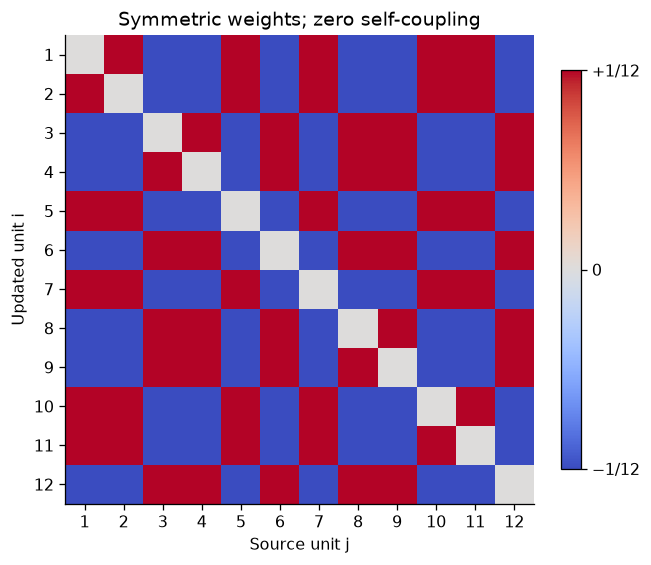

In [5]:
fig, ax = plt.subplots(figsize=(5.7, 4.8), layout="constrained")
im = ax.imshow(W, cmap="coolwarm", vmin=-1/12, vmax=1/12, interpolation="nearest")
ax.set(xticks=range(12), xticklabels=range(1, 13), yticks=range(12), yticklabels=range(1, 13),
       xlabel="Source unit j", ylabel="Updated unit i", title="Symmetric weights; zero self-coupling")
bar = fig.colorbar(im, ax=ax, ticks=[-1/12, 0, 1/12], shrink=.85)
bar.ax.set_yticklabels(["−1/12", "0", "+1/12"])
show_figure(fig, "weights")


## 3. A counterexample to unique recall

The energy depends on the **square** of overlap. Therefore $E(\xi)=E(-\xi)=-5.5$.
Both patterns are fixed points: $W\xi=(11/12)\xi$ and $W(-\xi)=(11/12)(-\xi)$.
Starting at the inverse cannot retrieve the designated positive pattern under these dynamics.
A nonincreasing energy alone does not identify which remembered pattern is the intended one.


In [6]:
inverse = hopfield_12(flipped_bits=tuple(range(12)))
np.testing.assert_array_equal(inverse.states, np.tile(-xi, (25, 1)))
np.testing.assert_allclose(W @ xi, (11/12) * xi)
np.testing.assert_allclose(W @ (-xi), (11/12) * (-xi))
assert hopfield_energy(xi, W) == hopfield_energy(-xi, W) == -5.5
assert inverse.energies[-1] == appendix["inverse_pattern_energy"]
print("Designated pattern energy:", hopfield_energy(xi, W))
print("Inverse pattern energy:   ", inverse.energies[-1])
print("Inverse retrieves designated pattern:", np.array_equal(inverse.states[-1], xi))


Designated pattern energy: -5.5
Inverse pattern energy:    -5.5
Inverse retrieves designated pattern: False


## 4. Change the corrupted cue

Flip the first $k$ bits for $k=0,\ldots,12$, keeping the order and two sweeps fixed.
Plot normalized overlap $m=\xi^Ts/12$: $+1$ means the designated pattern, $-1$ its inverse.
These are 13 selected cues, **not** an estimate of memory capacity or a recovery probability.
At six errors there is an equal split; which unit is updated first can decide the outcome.


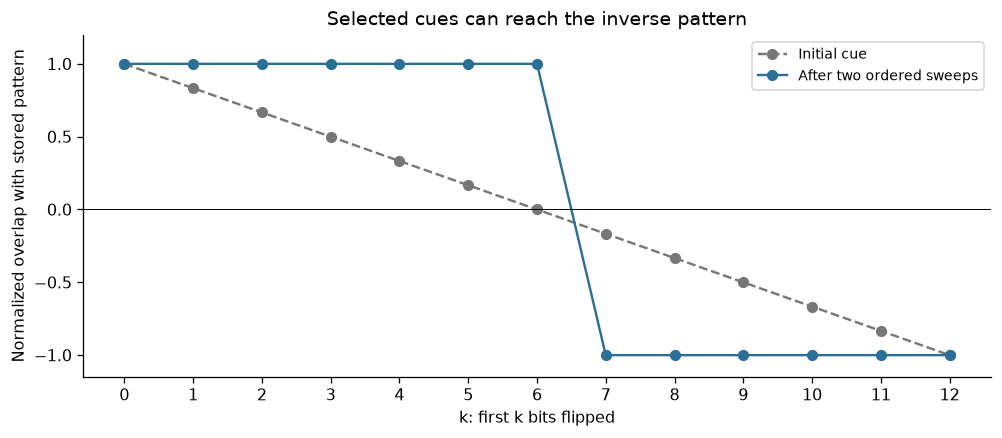

771

In [7]:
corruption_counts = np.arange(13)
trials = [hopfield_12(flipped_bits=tuple(range(int(k)))) for k in corruption_counts]
initial_overlap = np.array([trial.states[0] @ xi / 12 for trial in trials])
final_overlap = np.array([trial.states[-1] @ xi / 12 for trial in trials])
fig, ax = plt.subplots(figsize=(8.6, 3.7), layout="constrained")
ax.plot(corruption_counts, initial_overlap, "o--", color="#777777", label="Initial cue")
ax.plot(corruption_counts, final_overlap, "o-", color="#2a6f97", label="After two ordered sweeps")
ax.axhline(0, color="black", lw=.6)
ax.set(xlabel="k: first k bits flipped", ylabel="Normalized overlap with stored pattern",
       xticks=range(13), yticks=[-1, -.5, 0, .5, 1], ylim=(-1.15, 1.2),
       title="Selected cues can reach the inverse pattern")
ax.legend(fontsize=9)
show_figure(fig, "cue_intervention")
(OUTPUT / "results.json").write_text(json.dumps({
    "stored_pattern": xi.astype(int).tolist(), "flipped_indices": [0, 3, 7],
    "energy_trajectory": recall.energies.tolist(),
    "retrieves_pattern": bool(np.array_equal(recall.states[-1], xi)),
    "inverse_is_fixed": bool(np.all(inverse.states == -xi)),
    "prefix_corruption_final_overlaps": final_overlap.tolist(),
}, indent=2))


## Reflection and exercises

- Compare six flipped bits at indices `(0,1,2,3,4,5)` with `(6,7,8,9,10,11)`.
  They start with equal overlap and energy. Why does the first updated unit break the symmetry?
- At each energy drop, which wrong bit was repaired? What explains the flat steps after update 8?
- What conditions in the one-unit energy derivation would need reconsideration for simultaneous
  updates, asymmetric weights or nonzero self-coupling?
- What additional evidence would be needed to connect pattern completion in this network to
  biological, autobiographical or conscious memory?

Successful recovery of this cue is a concrete mechanism demonstration. It does not establish
universal recovery, human understanding, clinical utility or consciousness. Only one pattern is stored;
extending to multiple patterns changes the landscape. See [notebook 05](05_multistable_dynamics.ipynb)
for a different, two-pattern teaching example.

**Method reference:** Hopfield (1982), *Neural networks and physical systems with emergent collective
computational abilities*, [doi:10.1073/pnas.79.8.2554](https://doi.org/10.1073/pnas.79.8.2554).
The precise 12-unit configuration and trajectory are from this repository's manuscript appendix.
